# Lab: looking at the Nobel data

The warehouse is built. Now we use it the way a data scientist would: ask a question, get the numbers from the **gold** layer, and draw a chart to see the answer.

Every section follows the same three steps:

1. **Ask** the gold tables with SQL
2. **Draw** the result with matplotlib
3. **Read** the chart: what does it tell us?

We only use two tables, both built in notebook 2:

- `gold.dim_laureate`: one row per laureate (who they are)
- `gold.fct_award`: one row per award (what they won, and when)

## Setup

We open the database **read-only**: this notebook only looks at the data, it never changes it.

In [1]:
import duckdb
import matplotlib.pyplot as plt

con = duckdb.connect('../data/nobel.duckdb', read_only=True)

A few settings so that all charts share the same clean look. We use two colours in the whole notebook: blue for the main series, orange when there is a second one.

In [2]:
BLUE = '#2a78d6'
ORANGE = '#eb6834'

plt.rcParams.update({
    'figure.figsize': (8, 4),
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titlelocation': 'left',
    'axes.titleweight': 'bold',
    'font.size': 11,
})

---
## 1. People and organisations

Not every laureate is a person. How many of each do we have?

In [3]:
df = con.sql("""
    SELECT laureate_type, count(*) AS total
    FROM gold.dim_laureate
    GROUP BY laureate_type
    ORDER BY total
""").df()
df

,laureate_type,total
0,organisation,28
1,person,1000


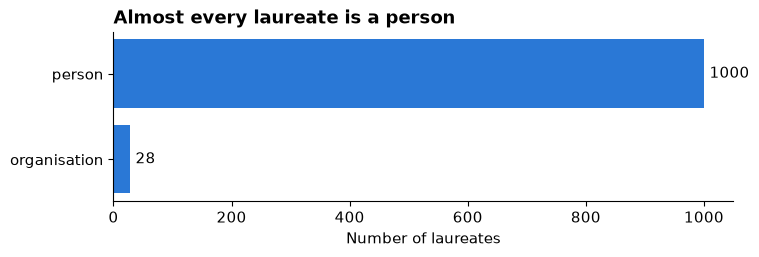

In [4]:
fig, ax = plt.subplots(figsize=(8, 2.2))
bars = ax.barh(df.laureate_type, df.total, color=BLUE)
ax.bar_label(bars, padding=4)
ax.set_title('Almost every laureate is a person')
ax.set_xlabel('Number of laureates')
plt.show()

**What we see:** 1000 people and only 28 organisations. Organisations are rare, so we look at them separately in section 3.

---
## 2. Men and women

Among the people, how many are men and how many are women?

In [5]:
df = con.sql("""
    SELECT gender, count(*) AS total
    FROM gold.dim_laureate
    WHERE laureate_type = 'person'
    GROUP BY gender
    ORDER BY total
""").df()
df

,gender,total
0,female,69
1,male,931


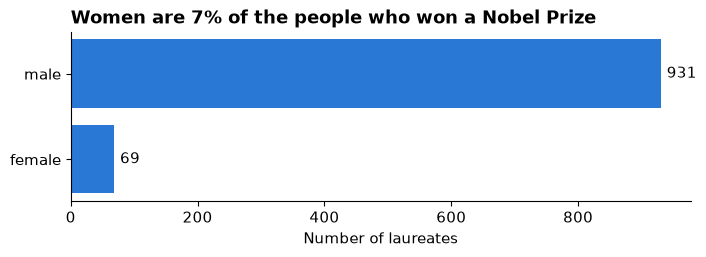

In [6]:
fig, ax = plt.subplots(figsize=(8, 2.2))
bars = ax.barh(df.gender, df.total, color=BLUE)
ax.bar_label(bars, padding=4)
ax.set_title('Women are 7% of the people who won a Nobel Prize')
ax.set_xlabel('Number of laureates')
plt.show()

**What we see:** 931 men and 69 women. Is this changing over time? We come back to it in section 6.

---
## 3. Which areas win prizes?

There are six categories. For each one we count the awards, separating people from organisations.

`count(*) FILTER (WHERE ...)` counts only the rows that pass the condition, so we get one column for people and one for organisations.

In [7]:
df = con.sql("""
    SELECT f.category,
           count(*) FILTER (WHERE l.laureate_type = 'person')       AS people,
           count(*) FILTER (WHERE l.laureate_type = 'organisation') AS organisations
    FROM gold.fct_award f
    JOIN gold.dim_laureate l USING (laureate_id)
    GROUP BY f.category
    ORDER BY count(*)
""").df()
df

,category,people,organisations
0,Economic Sciences,101,0
1,Literature,123,0
2,Peace,113,31
3,Chemistry,202,0
4,Physics,231,0
5,Physiology or Medicine,235,0


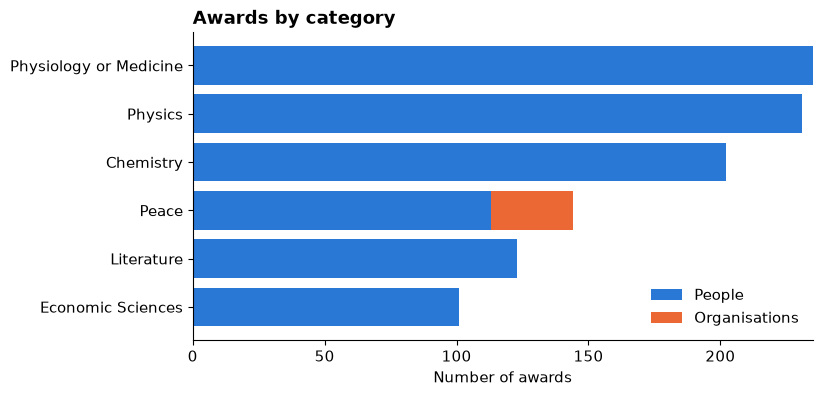

In [8]:
fig, ax = plt.subplots()
ax.barh(df.category, df.people, color=BLUE, label='People')
ax.barh(df.category, df.organisations, left=df.people, color=ORANGE, label='Organisations')
ax.set_title('Awards by category')
ax.set_xlabel('Number of awards')
ax.legend(frameon=False)
plt.show()

**What we see:**

- Medicine, Physics and Chemistry have the most awards, because their prizes are often shared by two or three people.
- Economic Sciences has the fewest: it only started in 1969.
- Organisations win in one category only: Peace.

---
## 4. How often are prizes awarded?

How many awards were given in each decade?

In [9]:
df = con.sql("""
    SELECT decade, count(*) AS awards
    FROM gold.fct_award
    GROUP BY decade
    ORDER BY decade
""").df()
df

,decade,awards
0,1900,57
1,1910,40
2,1920,54
3,1930,56
4,1940,43
5,1950,72
6,1960,79
7,1970,104
8,1980,97
9,1990,104


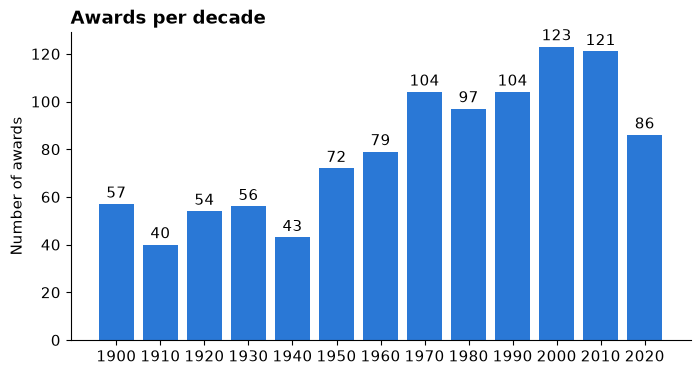

In [10]:
fig, ax = plt.subplots()
bars = ax.bar(df.decade.astype(str), df.awards, color=BLUE)
ax.bar_label(bars, padding=2)
ax.set_title('Awards per decade')
ax.set_ylabel('Number of awards')
plt.show()

**What we see:**

- The number of awards per decade has more than doubled since 1900.
- The dips in the 1910s and 1940s are the two World Wars, when some prizes were not awarded.
- The last bar is lower only because the 2020s are not finished yet.

The number of prizes per year did not double, so why are there more awards? The next chart answers that.

---
## 5. Are prizes shared more than before?

Each award has a `portion` (1, 1/2, 1/3 or 1/4). Adding up the portions gives the number of prizes. So:

> awards ÷ prizes = how many laureates share one prize, on average

In [11]:
df = con.sql("""
    SELECT decade,
           round(count(*) / sum(portion), 2) AS laureates_per_prize
    FROM gold.fct_award
    GROUP BY decade
    ORDER BY decade
""").df()
df

,decade,laureates_per_prize
0,1900,1.27
1,1910,1.11
2,1920,1.23
3,1930,1.27
4,1940,1.34
5,1950,1.50
6,1960,1.61
7,1970,1.76
8,1980,1.62
9,1990,1.73


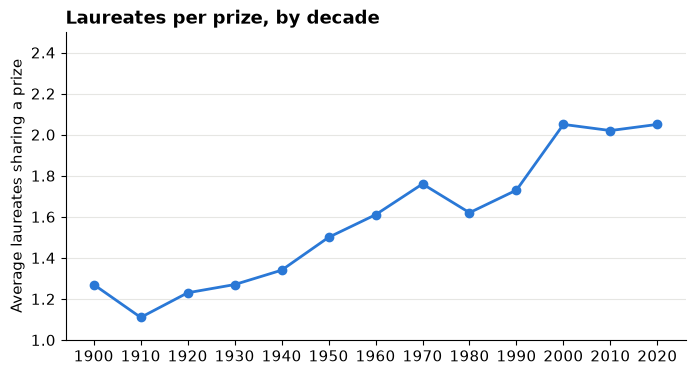

In [12]:
fig, ax = plt.subplots()
ax.plot(df.decade, df.laureates_per_prize, color=BLUE, linewidth=2, marker='o')
ax.set_ylim(1, 2.5)
ax.set_xticks(df.decade)
ax.grid(axis='y', color='#e6e6e3')
ax.set_title('Laureates per prize, by decade')
ax.set_ylabel('Average laureates sharing a prize')
plt.show()

**What we see:** in the 1900s a prize usually went to one person. Today a prize is shared by about two people on average. Research became teamwork.

---
## 6. Women over time

First the counts: men and women in each decade.

In [13]:
df = con.sql("""
    SELECT f.decade,
           count(*) FILTER (WHERE l.gender = 'male')   AS men,
           count(*) FILTER (WHERE l.gender = 'female') AS women
    FROM gold.fct_award f
    JOIN gold.dim_laureate l USING (laureate_id)
    WHERE l.laureate_type = 'person'
    GROUP BY f.decade
    ORDER BY f.decade
""").df()

df['percent_women'] = (100 * df.women / (df.men + df.women)).round(1)
df

,decade,men,women,percent_women
0,1900,53,3,5.4
1,1910,37,1,2.6
2,1920,52,2,3.7
3,1930,52,3,5.5
4,1940,37,3,7.5
5,1950,71,0,0.0
6,1960,72,3,4.0
7,1970,99,4,3.9
8,1980,90,4,4.3
9,1990,94,7,6.9


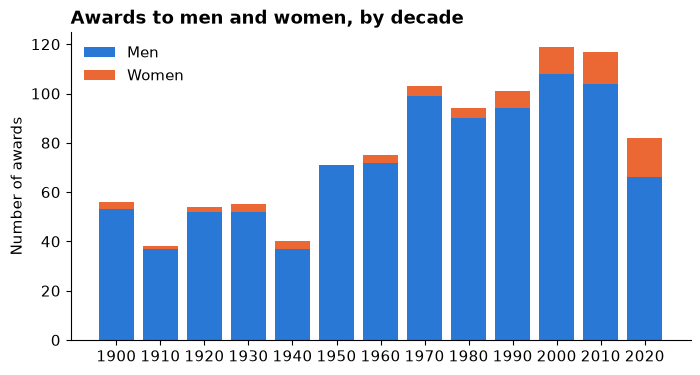

In [14]:
fig, ax = plt.subplots()
decades = df.decade.astype(str)
ax.bar(decades, df.men, color=BLUE, label='Men')
ax.bar(decades, df.women, bottom=df.men, color=ORANGE, label='Women')
ax.set_title('Awards to men and women, by decade')
ax.set_ylabel('Number of awards')
ax.legend(frameon=False)
plt.show()

The orange part is small in every decade. To see whether it is growing, we look at the **percentage** instead of the count.

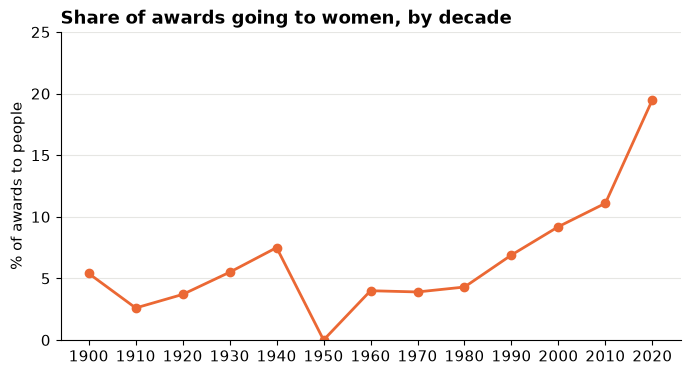

In [15]:
fig, ax = plt.subplots()
ax.plot(df.decade, df.percent_women, color=ORANGE, linewidth=2, marker='o')
ax.set_ylim(0, 25)
ax.set_xticks(df.decade)
ax.grid(axis='y', color='#e6e6e3')
ax.set_title('Share of awards going to women, by decade')
ax.set_ylabel('% of awards to people')
plt.show()

**What we see:** for a century the share of women stayed under 10%, and in the 1950s it was zero. It started to rise in the 1990s and reached almost 20% in the 2020s.

### Women by category

Is the share of women the same in every area?

In [16]:
df = con.sql("""
    SELECT f.category,
           round(100.0 * count(*) FILTER (WHERE l.gender = 'female') / count(*), 1) AS percent_women
    FROM gold.fct_award f
    JOIN gold.dim_laureate l USING (laureate_id)
    WHERE l.laureate_type = 'person'
    GROUP BY f.category
    ORDER BY percent_women
""").df()
df

,category,percent_women
0,Physics,2.2
1,Economic Sciences,3.0
2,Chemistry,4.0
3,Physiology or Medicine,6.0
4,Literature,15.4
5,Peace,18.6


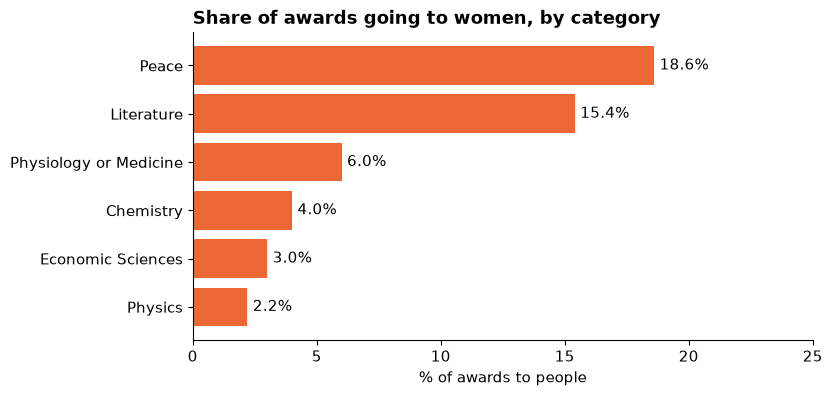

In [17]:
fig, ax = plt.subplots()
bars = ax.barh(df.category, df.percent_women, color=ORANGE)
ax.bar_label(bars, fmt='%.1f%%', padding=4)
ax.set_xlim(0, 25)
ax.set_title('Share of awards going to women, by category')
ax.set_xlabel('% of awards to people')
plt.show()

**What we see:** Peace and Literature have the highest share of women. Physics has the lowest.

---
## 7. How old are laureates when they win?

A histogram shows how the ages are spread: each bar counts the laureates in a 5-year age group.

In [18]:
df = con.sql("""
    SELECT category, award_year, decade, age_at_award
    FROM gold.fct_award
    WHERE age_at_award IS NOT NULL
""").df()

df.age_at_award.describe().round(1)

count    1005.0
mean       60.6
std        12.8
min        17.0
25%        52.0
50%        61.0
75%        70.0
max        97.0
Name: age_at_award, dtype: float64

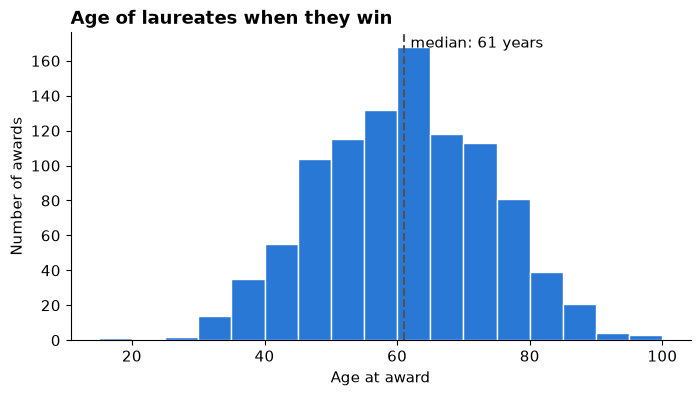

In [19]:
fig, ax = plt.subplots()
ax.hist(df.age_at_award, bins=range(15, 101, 5), color=BLUE, edgecolor='white')
ax.axvline(df.age_at_award.median(), color='#52514e', linestyle='--')
ax.text(df.age_at_award.median() + 1, ax.get_ylim()[1] * 0.95, f'median: {df.age_at_award.median():.0f} years')
ax.set_title('Age of laureates when they win')
ax.set_xlabel('Age at award')
ax.set_ylabel('Number of awards')
plt.show()

**What we see:** most laureates win between 50 and 70. Winning before 35 or after 85 is very rare.

### Age by category

A box plot compares the spread of several groups. The box holds the middle half of the laureates, and the line inside the box is the median.

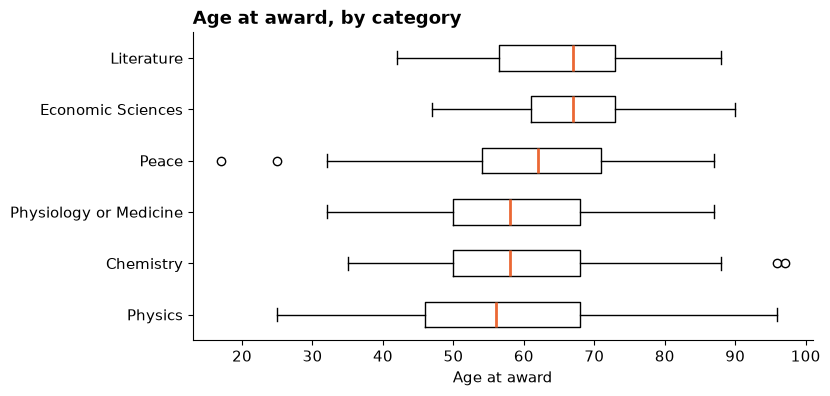

In [20]:
categories = df.groupby('category').age_at_award.median().sort_values().index
ages = [df[df.category == c].age_at_award for c in categories]

fig, ax = plt.subplots()
ax.boxplot(ages, orientation='horizontal', tick_labels=categories,
           medianprops={'color': ORANGE, 'linewidth': 2})
ax.set_title('Age at award, by category')
ax.set_xlabel('Age at award')
plt.show()

**What we see:** physicists tend to win youngest, economists and writers oldest. The circles are unusual cases: the youngest laureate of all won the Peace prize at 17.

### Are laureates getting older?

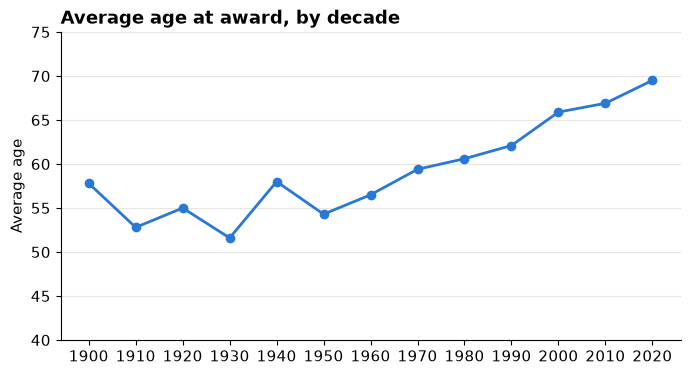

In [21]:
by_decade = df.groupby('decade').age_at_award.mean().round(1)

fig, ax = plt.subplots()
ax.plot(by_decade.index, by_decade.values, color=BLUE, linewidth=2, marker='o')
ax.set_ylim(40, 75)
ax.set_xticks(by_decade.index)
ax.grid(axis='y', color='#e6e6e3')
ax.set_title('Average age at award, by decade')
ax.set_ylabel('Average age')
plt.show()

**What we see:** the average age went from about 55 in the first half of the 20th century to almost 70 today.

---
## 8. Where do laureates come from?

The ten countries with the most awards. Remember the decision from notebook 2: `country` is the country that exists **today** at the place of birth.

In [22]:
df = con.sql("""
    SELECT l.country, count(*) AS awards
    FROM gold.fct_award f
    JOIN gold.dim_laureate l USING (laureate_id)
    WHERE l.country IS NOT NULL
    GROUP BY l.country
    ORDER BY awards DESC
    LIMIT 10
""").df()
df

,country,awards
0,USA,309
1,United Kingdom,97
2,Germany,86
3,France,66
4,Japan,32
5,Sweden,30
6,Russia,30
7,Poland,29
8,Switzerland,27
9,Canada,24


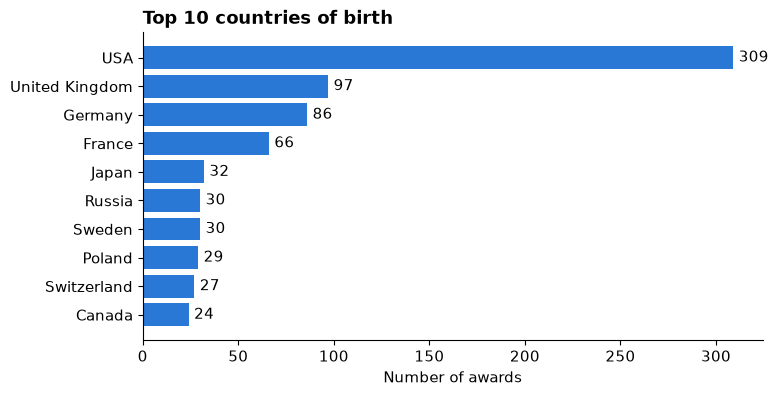

In [23]:
df = df.sort_values('awards')

fig, ax = plt.subplots()
bars = ax.barh(df.country, df.awards, color=BLUE)
ax.bar_label(bars, padding=4)
ax.set_title('Top 10 countries of birth')
ax.set_xlabel('Number of awards')
plt.show()

**What we see:** the USA has more awards than the next four countries together.

---
## Wrap-up

Every chart in this notebook came from two gold tables and a short query. That is the point of the medallion layers: the hard work (nested JSON, text that should be numbers, incomplete dates) was done once, in silver, and the analysis stays simple.

In [24]:
con.close()

### Try it yourself

Run the setup cells again to reconnect, then:

1. Draw the awards per decade for **one** category only (add a `WHERE category = 'Physics'`). Is the growth the same as in section 4?
2. Compare the average age of men and women at the time of the award.
3. Draw the share of women by decade for the Peace prize only.
4. Which five organisations won most often? (`laureate_type = 'organisation'`)